# 🐱 第 5 册：歌手大赛评委团 vs. 木匠师徒接力打磨（随机森林与 GBDT）

> **本册对话主角**：奶牛小猫**“团子”** × **“老橘师傅”**
> **对应《西瓜书》第 8 章（集成学习：Bagging 与 Boosting）**

![第6幕：歌手大赛评委团与木匠师徒接力](../assets/pic06-blindfold-vote-and-relay.svg)

---

## 一、顺着上集追问：一个人拿不准的时候，怎么找一群人商量？

**🐱 团子**：“师傅！要是遇到特别复杂的难题，不管是画直线、折纸还是颠铁锅，单个模型总是拿不准怎么办呀？俗话说‘三个臭皮匠，顶个诸葛亮’，我把同一个模型复制 50 份让它们一起投票行不行？”

**🍊 老橘师傅**：“哈哈，要是把同一个人的脑子复印 50 份，他看走眼的时候 50 个克隆人也会整齐划一地看走眼，投一万票也没用！
在《西瓜书》第 8 章里，真正的‘团队合作’有两种截然不同的生活智慧，一个是**歌手大赛评委团**，另一个是**木匠师徒接力打家具**：”

1. **第一招：歌手大赛评委团，各看各的求平均（随机森林 / Bagging）**
   要想让 30 个评委打出最公道的平均分，节目组会故意定规矩：
   * **1 号评委只准听高音准不准**，**2 号评委只准听节奏稳不稳**，**3 号评委只准看舞台表现力**（这就叫**随机抽样特征**）！
   * 单个评委可能今天心情激动打高了 2 分，另一个评委今天挑剔打低了 2 分，但因为大家看的维度不一样，把 30 个人的分数合在一起求个平均，各自手抖偏心的毛刺瞬间互相抵消，合成出了一条超丝滑的曲线！
2. **第二招：木匠师徒排成一排，后一个人专门修补前一个人的差价（GBDT / Boosting）**
   要做一件 100 分的雕花木雕，师徒三人不是同时各砍各的，而是**排成流水线接力补差价（残差）**：
   * **大徒弟拿大斧头（第 1 棒）**：先大刀阔斧砍出个粗毛坯，完成了 **60 分**，还留下 **`+40 分`的粗糙坑洼（这就叫残差）**；
   * **二徒弟拿木工刨（第 2 棒）**：他根本不用从头砍树！他的眼睛只盯着大徒弟留下的那 **`+40 分`坑洼**去推平，又补上了 **`+30 分`**，现在作品到了 $60+30=90$ 分，只剩 **`+10 分`**的小毛刺；
   * **老师傅拿细砂纸（第 3 棒）**：专门对着最后那 **`+10 分`细小毛刺**轻轻打磨，合体就是 $60+30+10=100$ 分！”

<details>
<summary>🐾 <b>老橘师傅的课本批注（为什么随机森林怕“克隆人”，GBDT 怕“步子迈太大”？）</b></summary>

* **随机森林的方差公式**：$\text{Var}(H) = \rho\sigma^2 + \frac{1-\rho}{T}\sigma^2$。其中 $\rho$ 是评委之间的相似跟风程度。如果所有树都用全部特征，大家都会抢着挑全村最强的那一个特征，变成 $\rho=0.8$ 的克隆人（看下面中图红线）；只有强制每棵树随机只看一部分特征，把 $\rho$ 压到 $0.05$（绿线），人多力量大的降方差威力才能彻底释放！
* **GBDT 的核心**：每一棵新树拟合的都不是原标签 $y$，而是上一轮留下的错题差价（负梯度 / 残差 $r_i = y_i - H_{m-1}(x_i)$）。

</details>

---

## 二、动手跑一跑：看 30 位评委怎么抵消手抖毛刺，看 20 棒木匠怎么接力磨出满分作品！

【集成学习双雄实测成绩单】
  [Bagging 降方差] 单棵深树测试 MSE = 0.0582 -> 30 棵深树并联平均后 MSE = 0.0224 (误差削减 61.6%)
  [GBDT 降偏差]   第 1 轮浅树测试 MSE = 0.2716 -> 第 4 轮 = 0.0408 -> 第 20 轮残差接力后 MSE = 0.0151!

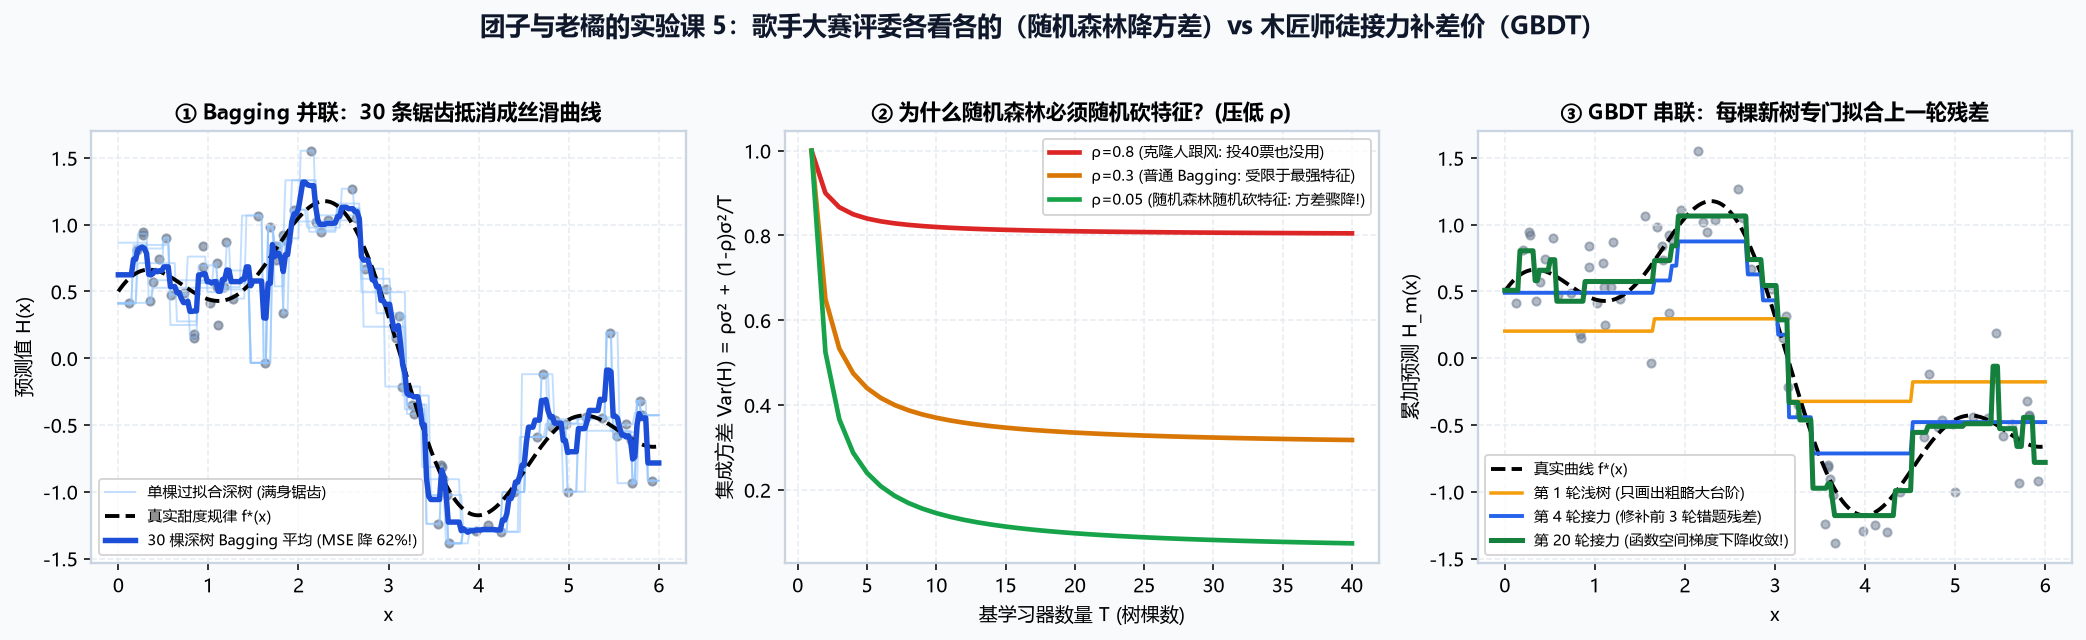

In [1]:
import numpy as np

# 实验 1 (左图 & 中图)：30 棵满身锯齿的深树同时投票 (Bagging/随机森林)，观察平均后锯齿如何消失！
# 实验 2 (右图)：20 棵只会画简单台阶的浅树排成一排接力补差价 (GBDT)，看第 1 棒 -> 第 4 棒 -> 第 20 棒如何逼近真曲线！
print("🐾 正在运行评委团并联投票与木匠师徒串联接力实验...")

### 🍊 老橘师傅带你看懂三张实验图

* 看**左图（评委团并联）**：浅蓝色细线是单个评委画出的剧烈锯齿，深蓝色粗线是 30 位评委平均后的结果，锯齿瞬间被抚平，测试误差大降！
* 看**中图（为什么要各看各的）**：红线（克隆人跟风 $\rho=0.8$）请再多评委也没用；绿线（随机分特征 $\rho=0.05$）人数越多越稳！
* 看**右图（木匠接力串联）**：第 1 棒大斧头（橙线）只能砍出粗糙大台阶；第 4 棒木工刨（蓝线）已经修出了波浪形；第 20 棒细砂纸（绿线）完美贴合了黑色真实规律线！